# Customer, order and returns analytics

**Audience:** executives, commercial teams, finance, operations and data practitioners.  
**Purpose:** audit three source files, explain commercial performance and evaluate a prospective return-risk model.  
**Workflow:** run each cell in order, or use **Kernel → Restart Kernel and Run All Cells**. Code outputs and figures are generated from the inputs; no conclusion should be copied without checking the data period and assumptions.

The sales and profit currency is not specified in the source. Values below are therefore in **source currency units**, not assumed to be dollars. Historical results do not establish future performance.

## 1. Setup and reproducibility

From the project root, install `requirements.txt` in a dedicated Python 3.11 environment and run `jupyter notebook`. Place the three CSVs in `data/raw/`. For a successful run from either the project root or `notebooks/`, this notebook resolves paths explicitly. Output files are generated under `reports/` and `models/`.

In [1]:
from pathlib import Path
import json, platform, warnings
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_score, recall_score, confusion_matrix)
import joblib
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'raw').exists() and (ROOT.parent / 'data' / 'raw').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'raw'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
MODELS = ROOT / 'models'
for p in (REPORTS, FIGURES, MODELS): p.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
print(f'Project folder: {ROOT.name}')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}')

Project folder: customer-analytics-portfolio
Python 3.11.0 | pandas 2.2.2 | NumPy 1.26.4 | SciPy 1.17.0 | scikit-learn 1.3.2


## 2. Load data and establish the grain

Read CSV columns as text first, preserving identifiers and source postal-code characters. A row in `orders` is a **line item**, not necessarily an entire order. The customers file has multiple location records for many IDs. The returns table records order IDs; it does not specify which lines or what value was returned.

In [2]:
raw = {name: pd.read_csv(DATA / f'{name}.csv', dtype='string')
       for name in ('customers', 'orders', 'returns')}
for name, frame in raw.items():
    print(f'{name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns')
    print('Columns:', ', '.join(frame.columns))

customers: 4,910 rows × 7 columns
Columns: Customer ID, Segment, Country, City, State, Postal Code, Region
orders: 9,994 rows × 14 columns
Columns: Row ID, Order ID, Order Date, Ship Date, Ship Mode, Customer ID, Product ID, Category, Sub-Category, Product Name, Sales, Quantity, Discount, Profit
returns: 296 rows × 2 columns
Columns: Returned, Order ID


## 3. Cleaning and data dictionary

The cleaning rules are intentionally conservative. Blank strings become missing; identifiers keep their source text; dates use the confirmed month/day/two-digit-year format. Numbers are parsed strictly. Original records are not silently deduplicated or dropped. Postal codes have different source lengths; zero-padding would be a data correction requiring confirmation, so no zeros are invented.

In [3]:
customers, orders, returns = (raw[n].copy() for n in ('customers', 'orders', 'returns'))
for frame in (customers, orders, returns):
    for col in frame.columns:
        frame[col] = frame[col].str.strip().replace('', pd.NA)
for col in ['Order Date', 'Ship Date']:
    orders[col] = pd.to_datetime(orders[col], format='%m/%d/%y', errors='raise')
for col in ['Sales', 'Quantity', 'Discount', 'Profit']:
    orders[col] = pd.to_numeric(orders[col], errors='raise')
if not orders['Quantity'].dropna().mod(1).eq(0).all():
    raise ValueError('Quantity contains non-integers; investigate before casting.')
orders['Quantity'] = orders['Quantity'].astype('Int64')
for frame, cols in [(customers, ['Segment','Country','State','Region']),
                    (orders, ['Ship Mode','Category','Sub-Category'])]:
    for col in cols: frame[col] = frame[col].astype('category')
allowed = {'Yes': True, 'No': False}
assert set(returns['Returned'].dropna()).issubset(allowed), 'Unexpected return flag'
returns['Returned'] = returns['Returned'].map(allowed).astype('boolean')

descriptions = {
'Customer ID':'Customer identifier','Segment':'Customer segment','Country':'Country',
'City':'City in customer record','State':'State in customer record','Postal Code':'Postal identifier',
'Region':'Region in customer record','Row ID':'Order line identifier','Order ID':'Order identifier',
'Order Date':'Date placed','Ship Date':'Date shipped','Ship Mode':'Shipping service',
'Product ID':'Product identifier','Category':'Product category','Sub-Category':'Product subcategory',
'Product Name':'Product label','Sales':'Line sales in source currency units',
'Quantity':'Units on line','Discount':'Discount proportion','Profit':'Line profit in source currency units',
'Returned':'Return indicator at order level'}
measure_cols = {'Sales','Quantity','Discount','Profit'}
def profile(frame):
    rows=[]
    for col in frame.columns:
        s = frame[col]
        row={'column':col,'dtype':str(s.dtype),'description':descriptions.get(col,''),
             'missing':int(s.isna().sum()),'unique':int(s.nunique())}
        for name in ('min','max','mean','median','std'):
            row[name] = getattr(s, name)() if col in measure_cols else np.nan
        if pd.api.types.is_datetime64_any_dtype(s):
            row['min'], row['max'] = s.min(), s.max()
        rows.append(row)
    return pd.DataFrame(rows).set_index('column')
for name, frame in [('customers',customers),('orders',orders),('returns',returns)]:
    display(Markdown(f'**{name.title()} profile**'))
    display(profile(frame))

**Customers profile**

,dtype,description,missing,unique,min,max,mean,median,std
column,,,,,,,,,
Customer ID,string,Customer identifier,0,793,NaN,NaN,NaN,NaN,NaN
Segment,category,Customer segment,0,3,NaN,NaN,NaN,NaN,NaN
Country,category,Country,0,1,NaN,NaN,NaN,NaN,NaN
City,string,City in customer record,0,531,NaN,NaN,NaN,NaN,NaN
State,category,State in customer record,0,49,NaN,NaN,NaN,NaN,NaN
Postal Code,string,Postal identifier,0,631,NaN,NaN,NaN,NaN,NaN
Region,category,Region in customer record,0,4,NaN,NaN,NaN,NaN,NaN


**Orders profile**

,dtype,description,missing,unique,min,max,mean,median,std
column,,,,,,,,,
Row ID,string,Order line identifier,0,9994,NaN,NaN,NaN,NaN,NaN
Order ID,string,Order identifier,0,5009,NaN,NaN,NaN,NaN,NaN
Order Date,datetime64[ns],Date placed,0,1237,2014-01-03 00:00:00,2017-12-30 00:00:00,NaN,NaN,NaN
Ship Date,datetime64[ns],Date shipped,0,1334,2014-01-07 00:00:00,2018-01-05 00:00:00,NaN,NaN,NaN
Ship Mode,category,Shipping service,0,4,NaN,NaN,NaN,NaN,NaN
Customer ID,string,Customer identifier,0,793,NaN,NaN,NaN,NaN,NaN
Product ID,string,Product identifier,0,1862,NaN,NaN,NaN,NaN,NaN
Category,category,Product category,0,3,NaN,NaN,NaN,NaN,NaN
Sub-Category,category,Product subcategory,0,17,NaN,NaN,NaN,NaN,NaN


**Returns profile**

,dtype,description,missing,unique,min,max,mean,median,std
column,,,,,,,,,
Returned,boolean,Return indicator at order level,0,1,NaN,NaN,NaN,NaN,NaN
Order ID,string,Order identifier,0,296,NaN,NaN,NaN,NaN,NaN


## 4. Quality checks before analysis

Checks are reported rather than concealed. Unique `Order ID` is not expected in the order-line table. Exact duplicates are counted, not discarded. Validation is limited to properties supported by the source; unexpected failures require investigation.

In [4]:
checks = pd.Series({
    'Exact duplicate customer records':int(customers.duplicated().sum()),
    'Exact duplicate order lines':int(orders.duplicated().sum()),
    'Exact duplicate return records':int(returns.duplicated().sum()),
    'Duplicate order-line IDs':int(orders['Row ID'].duplicated().sum()),
    'Missing key values':int(customers['Customer ID'].isna().sum() + orders[['Order ID','Customer ID']].isna().sum().sum() + returns['Order ID'].isna().sum()),
    'Orders with >1 customer':int((orders.groupby('Order ID')['Customer ID'].nunique() > 1).sum()),
    'Ship dates before order dates':int((orders['Ship Date'] < orders['Order Date']).sum()),
    'Nonpositive quantities':int(orders['Quantity'].le(0).sum()),
    'Discounts outside [0,1]':int((~orders['Discount'].between(0,1)).sum()),
    'Customer IDs with multiple location rows':int((customers.groupby('Customer ID').size()>1).sum()),
    'Order lines without a customer':int((~orders['Customer ID'].isin(customers['Customer ID'])).sum()),
    'Return IDs absent from orders':int((~returns['Order ID'].isin(orders['Order ID'])).sum()),
})
display(checks.to_frame('count'))
assert checks['Duplicate order-line IDs'] == 0 and checks['Missing key values'] == 0
assert checks['Orders with >1 customer'] == 0
assert not returns['Order ID'].duplicated().any(), 'Investigate duplicate return IDs before joining.'
print('Order-date coverage:', orders['Order Date'].min().date(), 'to', orders['Order Date'].max().date())

,count
Exact duplicate customer records,0
Exact duplicate order lines,0
Exact duplicate return records,0
Duplicate order-line IDs,0
Missing key values,0
Orders with >1 customer,0
Ship dates before order dates,0
Nonpositive quantities,0
"Discounts outside [0,1]",0
Customer IDs with multiple location rows,780


Order-date coverage: 2014-01-03 to 2017-12-30


## 5. Validated joins

Customer segment and country are joined only after verifying they do not vary within a customer ID. The remaining location fields are retained in the source table but cannot be assigned to an order without a location key. The absence of a return-file record is coded as `False` for the **observed return indicator**, assuming the file is complete for the analysis period. It is not proof that no return occurred outside the extract.

In [5]:
attrs = ['Segment','Country']
assert customers.groupby('Customer ID')[attrs].nunique(dropna=False).le(1).all().all()
profiles = customers[['Customer ID',*attrs]].drop_duplicates()
assert profiles['Customer ID'].is_unique
lines = orders.merge(profiles, on='Customer ID', how='left', validate='many_to_one', indicator='customer_match')
unmatched = int(lines['customer_match'].ne('both').sum())
assert unmatched == 0, f'{unmatched} order lines lack a customer profile'
lines = lines.drop(columns='customer_match')
lines = lines.merge(returns[['Order ID','Returned']], on='Order ID', how='left', validate='many_to_one')
lines['Returned'] = lines['Returned'].fillna(False).astype(bool)
assert len(lines) == len(orders)
for col in ['Sales','Quantity','Profit']:
    assert np.isclose(lines[col].sum(), orders[col].sum())
print(f'Join control: {len(lines):,} lines; {lines["Customer ID"].nunique():,} customers; {lines["Order ID"].nunique():,} orders; {unmatched} unmatched lines.')

Join control: 9,994 lines; 793 customers; 5,009 orders; 0 unmatched lines.


## 6. Build order-level and customer-level tables

Sales, profit and quantities are additive across lines. The quantity-weighted discount is a descriptive feature and is not a substitute for the true revenue-weighted discount. A return flag applies to the whole order, and does not reveal line-level returns. Both `Ship Mode` and customer `Segment` must be consistent within an order before we take the first value.

In [6]:
for col in ['Order Date','Customer ID','Segment','Ship Mode']:
    assert lines.groupby('Order ID', observed=True)[col].nunique(dropna=False).le(1).all(), f'Inconsistent {col} within order'
lines['discount_units'] = lines['Discount'] * lines['Quantity'].astype(float)
order_table = lines.groupby('Order ID', observed=True, as_index=False).agg(
    order_date=('Order Date','first'), customer_id=('Customer ID','first'),
    segment=('Segment','first'), ship_mode=('Ship Mode','first'),
    sales=('Sales','sum'), profit=('Profit','sum'), units=('Quantity','sum'),
    line_count=('Row ID','size'), category_count=('Category','nunique'),
    discount_units=('discount_units','sum'), returned=('Returned','max'))
order_table['discount_weighted'] = order_table['discount_units'] / order_table['units'].astype(float).replace(0,np.nan)
order_table['month'] = order_table['order_date'].dt.month
customer_table = order_table.groupby('customer_id', observed=True, as_index=False).agg(
    orders=('Order ID','nunique'), sales=('sales','sum'), profit=('profit','sum'),
    first_order=('order_date','min'), last_order=('order_date','max'))
assert len(order_table) == orders['Order ID'].nunique()
assert len(customer_table) == orders['Customer ID'].nunique()
assert np.isclose(order_table['sales'].sum(), lines['Sales'].sum())
display(pd.DataFrame({'table':['order lines','orders','customers'],
                      'rows':[len(lines),len(order_table),len(customer_table)]}))

,table,rows
0,order lines,9994
1,orders,5009
2,customers,793


## 7. Executive overview

All monetary figures are in the source's unspecified currency units. Margin is total profit divided by total sales. Return rate uses unique orders, not line items. The extract covers an historical period and may not describe the current business.

In [7]:
sales_total, profit_total = order_table['sales'].sum(), order_table['profit'].sum()
overview = pd.Series({
    'Order lines':len(lines), 'Orders':len(order_table), 'Customers':len(customer_table),
    'Sales (source units)':sales_total, 'Profit (source units)':profit_total,
    'Margin':profit_total / sales_total, 'Average order value':sales_total / len(order_table),
    'Returned orders (observed)':int(order_table['returned'].sum()),
    'Observed return rate':order_table['returned'].mean()})
display(overview.to_frame('value'))
print('Interpretation: returning an order is tracked at order level; line-item refund amounts are unavailable.')

,value
Order lines,"9,994.000"
Orders,"5,009.000"
Customers,793.000
Sales (source units),"2,297,200.860"
Profit (source units),"286,397.022"
Margin,0.125
Average order value,458.615
Returned orders (observed),296.000
Observed return rate,0.059


Interpretation: returning an order is tracked at order level; line-item refund amounts are unavailable.


## 8. Trends and seasonality

Monthly totals are assigned by order date. The monthly curve is descriptive; a year-over-year comparison should compare matching months and avoid treating incomplete years as full years.

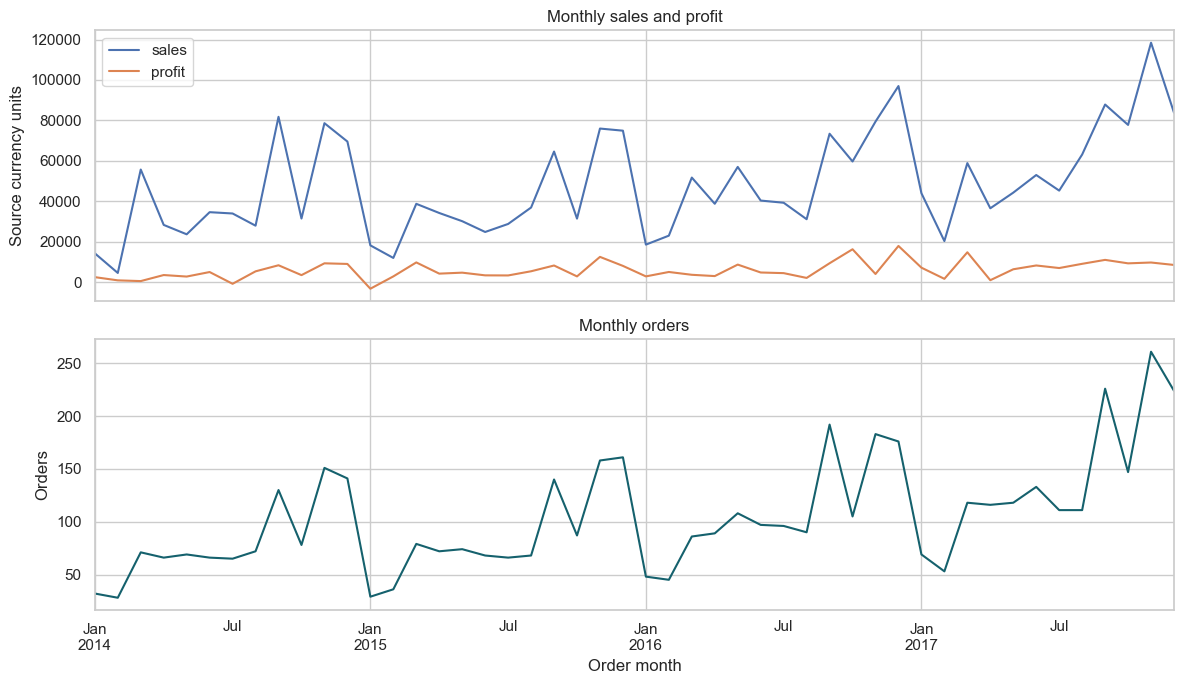

,sales,profit,orders,margin,sales_yoy
year,,,,,
2014,"484,247.498","49,543.974",969,0.102,<NA>
2015,"470,532.509","61,618.604",1038,0.131,-0.028
2016,"609,205.598","81,795.174",1315,0.134,0.295
2017,"733,215.255","93,439.270",1687,0.127,0.204


Compare years cautiously when the first or last year is incomplete.


In [8]:
monthly = order_table.assign(month_start=order_table['order_date'].dt.to_period('M').dt.to_timestamp()).groupby('month_start').agg(
    sales=('sales','sum'),profit=('profit','sum'),orders=('Order ID','nunique'))
fig, ax = plt.subplots(2, 1, figsize=(12,7), sharex=True)
monthly[['sales','profit']].plot(ax=ax[0]); ax[0].set(title='Monthly sales and profit',ylabel='Source currency units')
monthly['orders'].plot(ax=ax[1],color='#15616d'); ax[1].set(title='Monthly orders',ylabel='Orders',xlabel='Order month')
fig.tight_layout(); fig.savefig(FIGURES/'monthly_trends.png',dpi=150,bbox_inches='tight'); plt.show()
annual = order_table.assign(year=order_table['order_date'].dt.year).groupby('year').agg(sales=('sales','sum'),profit=('profit','sum'),orders=('Order ID','nunique'))
annual['margin'] = annual['profit']/annual['sales']
annual['sales_yoy'] = annual['sales'].pct_change()
display(annual)
print('Compare years cautiously when the first or last year is incomplete.')

## 9. Product, customer and discount patterns

Category results are computed from lines; customer concentration and return metrics are computed from orders. Values describe the observed history; they do not identify causal drivers. Discount bands describe the stated line discount, rather than an estimated causal impact of discounting.

,Category,Sub-Category,sales,profit,units,lines,margin
3,Furniture,Tables,"206,965.532","-17,725.481",1241,319,-0.086
0,Furniture,Bookcases,"114,879.996","-3,472.556",868,228,-0.030
12,Office Supplies,Supplies,"46,673.538","-1,189.100",647,190,-0.025
8,Office Supplies,Fasteners,"3,024.280",949.518,914,217,0.314
15,Technology,Machines,"189,238.631","3,384.757",440,115,0.018
9,Office Supplies,Labels,"12,486.312","5,546.254",1400,364,0.444
5,Office Supplies,Art,"27,118.792","6,527.787",3000,796,0.241
7,Office Supplies,Envelopes,"16,476.402","6,964.177",906,254,0.423


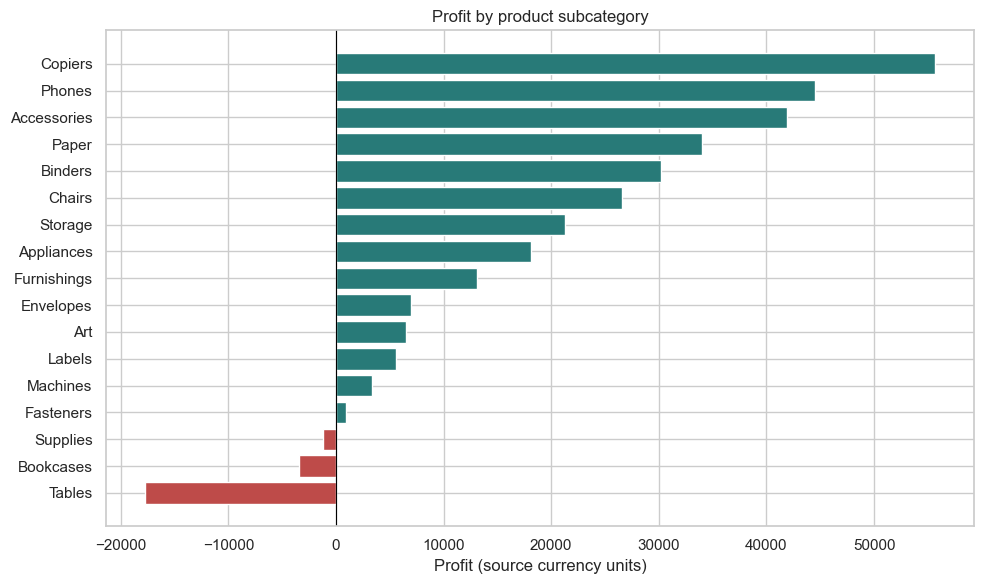

,orders,customers,sales,profit,return_rate,margin
segment,,,,,,
Consumer,2586,409,"1,161,401.345","134,119.209",0.060,0.115
Corporate,1514,236,"706,146.367","91,979.134",0.061,0.130
Home Office,909,148,"429,653.149","60,298.679",0.054,0.140


,lines,sales,profit,margin
discount_band,,,,
0%,4798,"1,087,908.470","320,987.603",0.295
>0–10%,94,"54,369.351","9,029.177",0.166
>10–20%,3709,"792,152.890","91,756.298",0.116
>20–40%,460,"234,137.898","-35,817.465",-0.153
>40%,933,"128,632.252","-99,558.591",-0.774


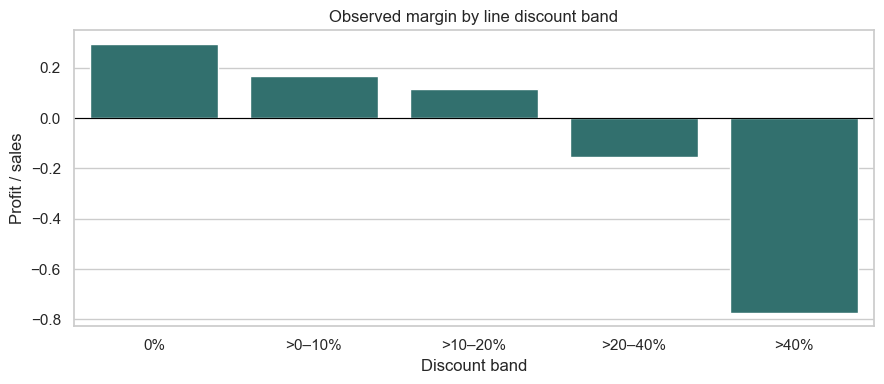

Top 20% of customers (rounded up to 159) account for 48.1% of observed sales.
Single-order customers: 12 of 793.


In [9]:
category = lines.groupby(['Category','Sub-Category'],observed=True).agg(
    sales=('Sales','sum'),profit=('Profit','sum'),units=('Quantity','sum'),lines=('Row ID','size')).reset_index()
category['margin'] = category['profit']/category['sales'].replace(0,np.nan)
display(category.sort_values('profit').head(8))
fig, ax = plt.subplots(figsize=(10,6))
chart = category.sort_values('profit')
ax.barh(chart['Sub-Category'].astype(str),chart['profit'],color=np.where(chart['profit']<0,'#be4b49','#287a78'))
ax.axvline(0,color='black',linewidth=.8); ax.set(title='Profit by product subcategory',xlabel='Profit (source currency units)')
fig.tight_layout(); fig.savefig(FIGURES/'subcategory_profit.png',dpi=150,bbox_inches='tight'); plt.show()

segment = order_table.groupby('segment', observed=True).agg(orders=('Order ID','size'),customers=('customer_id','nunique'),sales=('sales','sum'),profit=('profit','sum'),return_rate=('returned','mean'))
segment['margin'] = segment['profit']/segment['sales']
display(segment)

lines['discount_band'] = pd.cut(lines['Discount'],[-.001,0,.1,.2,.4,1],labels=['0%','>0–10%','>10–20%','>20–40%','>40%'])
discounts = lines.groupby('discount_band',observed=True).agg(lines=('Row ID','size'),sales=('Sales','sum'),profit=('Profit','sum'))
discounts['margin'] = discounts['profit']/discounts['sales']
display(discounts)
fig, ax = plt.subplots(figsize=(9,4)); sns.barplot(x=discounts.index.astype(str),y=discounts['margin'],color='#287a78',ax=ax)
ax.axhline(0,color='black',lw=.8); ax.set(title='Observed margin by line discount band',xlabel='Discount band',ylabel='Profit / sales')
fig.tight_layout(); fig.savefig(FIGURES/'discount_margin.png',dpi=150,bbox_inches='tight'); plt.show()

ranked = customer_table.sort_values('sales',ascending=False).reset_index(drop=True)
top_n = max(1,int(np.ceil(.2*len(ranked))))
top_share = ranked.iloc[:top_n]['sales'].sum()/ranked['sales'].sum()
print(f'Top 20% of customers (rounded up to {top_n}) account for {top_share:.1%} of observed sales.')
print(f'Single-order customers: {(customer_table["orders"]==1).sum():,} of {len(customer_table):,}.')

## 10. Inference: uncertainty and association

**Customer-cluster bootstrap:** sample customers, including all their orders, to estimate a 95% interval for the overall profit margin. This accounts for repeated orders per customer, but remains conditional on the extract and is not a forecast.

**Segment and observed returns:** report a chi-square association and Cramér's V alongside the contingency table. Multiple orders from the same customer violate the test's simple independence assumption, so its p-value is exploratory. To address dependence, a customer-cluster permutation test shuffles each customer's segment label between customers while retaining their orders. Both tests assume labels and observed returns are correctly recorded. Neither establishes causality.

In [10]:
cluster = customer_table[['sales','profit']].to_numpy(dtype=float)
rng = np.random.default_rng(SEED)
boot = np.empty(2000)
for i in range(len(boot)):
    sample = cluster[rng.integers(0,len(cluster),len(cluster))]
    boot[i] = sample[:,1].sum()/sample[:,0].sum()
margin_ci = np.quantile(boot,[.025,.975])
print(f'Customer-cluster bootstrap, 95% margin interval: {margin_ci[0]:.2%} to {margin_ci[1]:.2%} (2,000 resamples).')

cont = pd.crosstab(order_table['segment'],order_table['returned'])
chi2, p_chi, dof, expected = stats.chi2_contingency(cont,correction=False)
cramers_v = np.sqrt(chi2/(cont.to_numpy().sum()*min(cont.shape[0]-1,cont.shape[1]-1)))
display(cont.rename(columns={False:'not observed returned',True:'observed returned'}))
print(f'Exploratory chi-square p={p_chi:.4g}; Cramér V={cramers_v:.3f}; minimum expected count={expected.min():.1f}.')
cust_seg = order_table[['customer_id','segment']].drop_duplicates()
assert cust_seg['customer_id'].is_unique
cust_return = order_table.groupby('customer_id',observed=True).agg(n=('returned','size'),r=('returned','sum')).reset_index()
perm_data = cust_return.merge(cust_seg,on='customer_id',validate='one_to_one')
def cluster_stat(labels, n, r):
    cats, inverse = np.unique(labels,return_inverse=True)
    counts=np.bincount(inverse,weights=n,minlength=len(cats))
    returned=np.bincount(inverse,weights=r,minlength=len(cats))
    table=np.column_stack([counts-returned,returned])
    return stats.chi2_contingency(table,correction=False)[0]
labels=perm_data['segment'].astype(str).to_numpy()
n=perm_data['n'].to_numpy(); r=perm_data['r'].to_numpy()
observed=cluster_stat(labels,n,r)
permuted=np.array([cluster_stat(rng.permutation(labels),n,r) for _ in range(1999)])
p_cluster=(1+(permuted>=observed).sum())/(len(permuted)+1)
print(f'Customer-cluster permutation p={p_cluster:.4f} (1,999 permutations; null: segment labels exchangeable across customers).')
print('This is one pre-specified association test; do not interpret exploratory comparisons as causal.')

Customer-cluster bootstrap, 95% margin interval: 10.56% to 14.34% (2,000 resamples).


returned,not observed returned,observed returned
segment,,
Consumer,2432,154
Corporate,1421,93
Home Office,860,49


Exploratory chi-square p=0.7415; Cramér V=0.011; minimum expected count=53.7.
Customer-cluster permutation p=0.7280 (1,999 permutations; null: segment labels exchangeable across customers).
This is one pre-specified association test; do not interpret exploratory comparisons as causal.


## 11. Predictive problem and leakage controls

**Use case:** rank orders for a possible manual review at the time an order is placed. Target: whether its ID appears in the provided returns file. Available features are planned ship mode, known customer segment, order month, item count, units, number of product categories, sales and quantity-weighted discount. Profit, ship date, return fields, customer identifiers and any later information are excluded.

**Validation:** the final calendar year is a strictly later holdout. The preceding year is validation for model choice; earlier years train candidates. The validation winner is refit on all pre-holdout orders and evaluated once on the holdout. Average precision is the selection metric because returns are uncommon; prevalence is the no-skill baseline. ROC AUC, Brier score and precision/recall among the top 10% ranked orders are also reported.

**Known limitation:** no return date or label-maturity window is available. We cannot verify that labels were known at each training cutoff; the final period may also be right-censored. Treat this as a retrospective prototype, not production evidence. Repeat with mature, dated outcomes before deployment.

In [11]:
numeric_features=['sales','units','line_count','category_count','discount_weighted','month']
categorical_features=['segment','ship_mode']
features=numeric_features+categorical_features
model_data=order_table.sort_values(['order_date','Order ID']).copy()
model_data['units'] = model_data['units'].astype(float)
model_data[categorical_features] = model_data[categorical_features].astype('object')
holdout_year=int(model_data['order_date'].dt.year.max())
validation_year=holdout_year-1
train=model_data[model_data['order_date'].dt.year < validation_year]
valid=model_data[model_data['order_date'].dt.year == validation_year]
test=model_data[model_data['order_date'].dt.year == holdout_year]
assert min(len(train),len(valid),len(test))>0
assert train['order_date'].max() < valid['order_date'].min() < test['order_date'].min()
assert all(frame['returned'].nunique()==2 for frame in [train,valid,test])
print(pd.DataFrame([{'split':name,'first':d['order_date'].min().date(),'last':d['order_date'].max().date(),'orders':len(d),'returns':int(d['returned'].sum()),'prevalence':d['returned'].mean()} for name,d in [('train',train),('validation',valid),('holdout',test)]]))

def preprocessor():
    numeric = Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    categorical = Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('numeric',numeric,numeric_features),('categorical',categorical,categorical_features)])

candidates={
    'baseline':Pipeline([('prep',preprocessor()),('model',DummyClassifier(strategy='prior'))]),
    'logistic':Pipeline([('prep',preprocessor()),('model',LogisticRegression(max_iter=2000,random_state=SEED))]),
    'random_forest':Pipeline([('prep',preprocessor()),('model',RandomForestClassifier(n_estimators=250,min_samples_leaf=12,random_state=SEED,n_jobs=1))])}

validation_rows=[]
for name, estimator in candidates.items():
    estimator.fit(train[features],train['returned'].astype(int))
    prob=estimator.predict_proba(valid[features])[:,1]
    validation_rows.append({'model':name,'average_precision':average_precision_score(valid['returned'],prob),'roc_auc':roc_auc_score(valid['returned'],prob),'brier':brier_score_loss(valid['returned'],prob)})
validation_results=pd.DataFrame(validation_rows).set_index('model').sort_values('average_precision',ascending=False)
display(validation_results)
winner=validation_results.index[0]
print('Validation winner:',winner,'| baseline AP ≈ validation prevalence:',round(valid['returned'].mean(),4))

        split       first        last  orders  returns  prevalence
0       train  2014-01-03  2015-12-31    2007      114       0.057
1  validation  2016-01-02  2016-12-31    1315       77       0.059
2     holdout  2017-01-01  2017-12-30    1687      105       0.062


,average_precision,roc_auc,brier
model,,,
random_forest,0.089,0.564,0.055
logistic,0.088,0.551,0.055
baseline,0.059,0.500,0.055


Validation winner: random_forest | baseline AP ≈ validation prevalence: 0.0586


,holdout_value
holdout_orders,"1,687.000"
holdout_returns,105.000
prevalence,0.062
average_precision,0.114
roc_auc,0.641
brier,0.057
top_10_percent_count,169.000
precision_at_top_10_percent,0.154
recall_at_top_10_percent,0.248
baseline_precision,0.062


C:\Users\baina\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\baina\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\baina\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.g

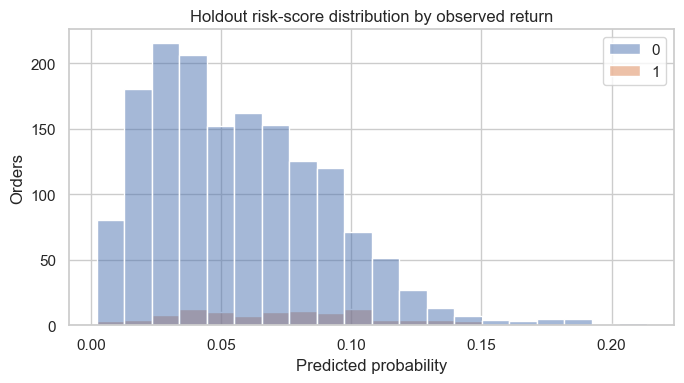

Model artifact saved locally to models/return_risk.joblib; do not use for automated customer decisions.


In [12]:
final_model=candidates[winner]
development=pd.concat([train,valid]).sort_values('order_date')
final_model.fit(development[features],development['returned'].astype(int))
test_prob=final_model.predict_proba(test[features])[:,1]
test_y=test['returned'].astype(int).to_numpy()
k=max(1,int(np.ceil(.1*len(test))))
top=np.argsort(-test_prob,kind='stable')[:k]
test_metrics={
    'holdout_orders':int(len(test)), 'holdout_returns':int(test_y.sum()),
    'prevalence':float(test_y.mean()), 'average_precision':float(average_precision_score(test_y,test_prob)),
    'roc_auc':float(roc_auc_score(test_y,test_prob)), 'brier':float(brier_score_loss(test_y,test_prob)),
    'top_10_percent_count':int(k), 'precision_at_top_10_percent':float(test_y[top].mean()),
    'recall_at_top_10_percent':float(test_y[top].sum()/test_y.sum()),
    'baseline_precision':float(test_y.mean())}
display(pd.Series(test_metrics).to_frame('holdout_value'))

fig,ax=plt.subplots(figsize=(7,4)); sns.histplot(x=test_prob,hue=test_y.astype(str),bins=20,stat='count',common_norm=False,ax=ax)
ax.set(title='Holdout risk-score distribution by observed return',xlabel='Predicted probability',ylabel='Orders')
fig.tight_layout(); fig.savefig(FIGURES/'holdout_risk_scores.png',dpi=150,bbox_inches='tight'); plt.show()

joblib.dump({'model':final_model,'features':features,'model_name':winner,'trained_through':str(development['order_date'].max().date()),'holdout_metrics':test_metrics}, MODELS/'return_risk.joblib')
(REPORTS/'model_metrics.json').write_text(json.dumps(test_metrics,indent=2),encoding='utf-8')
print('Model artifact saved locally to models/return_risk.joblib; do not use for automated customer decisions.')

## 12. Deployment design and controls

The included `src/score_batch.py` is a reproducible **local batch-scoring prototype**, not a deployed service. It expects one order per row with exactly the documented feature names. Run it only with an artifact trained in your own trusted environment. It validates the schema, numeric ranges and nonnegative order amounts, then outputs probabilities; it does not include customer identifiers unless the input carries a separate reference column.

Before operational use: secure the source data and artifacts; define outcome maturity and the review intervention; confirm permissible use and segment fairness with business owners; test on recent data; choose a threshold based on review capacity and costs; monitor feature drift, calibration, data quality and eventual outcomes; maintain model/version ownership, audit logs and rollback. A model score is a prioritization signal, not an automatic decision.

## 13. Management brief and limitations

The cell below writes a concise report using the computed outputs. The report explicitly describes what can and cannot be inferred. Values may change if the input extract changes. For sensitive company data, review notebook outputs, aggregate numbers and figures before publishing to a public repository.

In [13]:
worst = category.sort_values('profit').iloc[0]
best = category.sort_values('profit',ascending=False).iloc[0]
brief = f"""# Executive report: customer, order and return analysis

## Scope and decision context
The extract covers {order_table['order_date'].min().date()} to {order_table['order_date'].max().date()}. It contains {len(lines):,} order lines, {len(order_table):,} orders and {len(customer_table):,} purchasing customers. Monetary figures are in the source's unspecified currency units. These are historical results, not current performance.

## Main findings
* Sales: {sales_total:,.2f}; recorded profit: {profit_total:,.2f}; aggregate margin: {profit_total/sales_total:.2%}. Customer-cluster bootstrap 95% margin interval: {margin_ci[0]:.2%}–{margin_ci[1]:.2%}; this describes sampling uncertainty under the stated assumptions, not forecasting uncertainty.
* The subcategory with the highest observed profit was {best['Sub-Category']} ({best['profit']:,.2f}); the lowest was {worst['Sub-Category']} ({worst['profit']:,.2f}). Investigate product mix, pricing and costs before acting.
* The top fifth of customers by observed sales contributed {top_share:.1%} of sales. Concentration may affect planning, but the extract alone does not explain why customers buy.
* {int(order_table['returned'].sum()):,} of {len(order_table):,} orders appeared in the returns file ({order_table['returned'].mean():.2%}). This is an order-level indicator, not a refund value or line-level return rate.
* Segment and return association: Cramér's V {cramers_v:.3f}; customer-cluster permutation p-value {p_cluster:.4f}. This is exploratory, dependent on recorded labels and cannot establish cause.

## Actions by team
* **Commercial and category managers:** review the lowest-profit subcategories and discount bands alongside volume and customer mix; test changes in a controlled pilot.
* **Finance:** validate currency, definitions of sales and profit, and the accounting treatment and amount of returns before using the totals for financial reporting.
* **Operations and customer experience:** review the return process and record return dates, reasons, affected lines and refunded amounts.
* **Data team:** add a reliable order-location key, retain time-stamped order and return events, and document the reporting extract and label-maturity rules.

## Prediction prototype
Selected on {validation_year} validation: {winner}. Tested on the later {holdout_year} holdout: average precision {test_metrics['average_precision']:.3f} versus observed return prevalence {test_metrics['prevalence']:.3f}; ROC AUC {test_metrics['roc_auc']:.3f}; Brier score {test_metrics['brier']:.3f}. Among the {k:,} highest-ranked orders (about 10%), precision was {test_metrics['precision_at_top_10_percent']:.1%} and recall {test_metrics['recall_at_top_10_percent']:.1%}. Ranking ties, cost of review and calibration matter; these results do not establish business value.

## Limitations
No return-event date or outcome-maturity window is supplied; model evaluation may include immature or unavailable labels. The customer table has multiple location records for many customers and no order-location key. The return file identifies orders, not returned items or refunds. Observational patterns are not causal. Customer and product records may be incomplete outside the extract. Review data rights and all outputs before public sharing.
"""
(REPORTS/'executive_report.md').write_text(brief,encoding='utf-8')
display(Markdown(brief))

# Refresh the browser-readable brief when the input data change.
import mistune
report_body = mistune.html(brief)
report_page = f"""<!doctype html><html lang='en'><head><meta charset='utf-8'><meta name='viewport' content='width=device-width,initial-scale=1'><title>Executive report | Customer analytics</title><style>body{{font:16px/1.7 system-ui,sans-serif;color:#162b34;background:#f2f5f6;margin:0}}main{{max-width:1000px;margin:40px auto;padding:48px;background:white}}h1{{color:#102d38;line-height:1.2}}h2{{color:#155c60;border-bottom:1px solid #d8e6e6}}li{{margin:.65em 0}}img{{max-width:100%;height:auto}}@media print{{main{{margin:0;padding:0}}}}</style></head><body><main>{report_body}<h2>Supporting visuals</h2><figure><img src='figures/monthly_trends.png' alt='Monthly sales, profit and order counts'></figure><figure><img src='figures/subcategory_profit.png' alt='Profit by product subcategory'></figure></main></body></html>"""
(REPORTS/'executive_report.html').write_text(report_page, encoding='utf-8')

# Executive report: customer, order and return analysis

## Scope and decision context
The extract covers 2014-01-03 to 2017-12-30. It contains 9,994 order lines, 5,009 orders and 793 purchasing customers. Monetary figures are in the source's unspecified currency units. These are historical results, not current performance.

## Main findings
* Sales: 2,297,200.86; recorded profit: 286,397.02; aggregate margin: 12.47%. Customer-cluster bootstrap 95% margin interval: 10.56%–14.34%; this describes sampling uncertainty under the stated assumptions, not forecasting uncertainty.
* The subcategory with the highest observed profit was Copiers (55,617.82); the lowest was Tables (-17,725.48). Investigate product mix, pricing and costs before acting.
* The top fifth of customers by observed sales contributed 48.1% of sales. Concentration may affect planning, but the extract alone does not explain why customers buy.
* 296 of 5,009 orders appeared in the returns file (5.91%). This is an order-level indicator, not a refund value or line-level return rate.
* Segment and return association: Cramér's V 0.011; customer-cluster permutation p-value 0.7280. This is exploratory, dependent on recorded labels and cannot establish cause.

## Actions by team
* **Commercial and category managers:** review the lowest-profit subcategories and discount bands alongside volume and customer mix; test changes in a controlled pilot.
* **Finance:** validate currency, definitions of sales and profit, and the accounting treatment and amount of returns before using the totals for financial reporting.
* **Operations and customer experience:** review the return process and record return dates, reasons, affected lines and refunded amounts.
* **Data team:** add a reliable order-location key, retain time-stamped order and return events, and document the reporting extract and label-maturity rules.

## Prediction prototype
Selected on 2016 validation: random_forest. Tested on the later 2017 holdout: average precision 0.114 versus observed return prevalence 0.062; ROC AUC 0.641; Brier score 0.057. Among the 169 highest-ranked orders (about 10%), precision was 15.4% and recall 24.8%. Ranking ties, cost of review and calibration matter; these results do not establish business value.

## Limitations
No return-event date or outcome-maturity window is supplied; model evaluation may include immature or unavailable labels. The customer table has multiple location records for many customers and no order-location key. The return file identifies orders, not returned items or refunds. Observational patterns are not causal. Customer and product records may be incomplete outside the extract. Review data rights and all outputs before public sharing.


3704

## 14. Handoff checklist

1. Confirm data provenance, currency and the interpretation of sales, profit and returns with the owners.
2. Review quality checks and all join controls; do not assign ambiguous locations.
3. Confirm the observation period and data completeness before using business results.
4. Rebuild the environment and rerun the notebook end to end.
5. Review data rights, figures and notebook outputs before a public GitHub push. Raw data, local models and caches are ignored by `.gitignore`; aggregate results may still be sensitive.
6. Use the batch scorer only as a prototype. A production release requires a separate data contract, outcome timestamps, security, monitoring and documented approval.